(sec-7-4)=
# 7.4 Autoregressive Spectral Estimation

Short-term heart rate variability is measured on five-minute recordings, and brain–computer interfaces decide what a user intends from one or two seconds of EEG. Welch's method struggles with records this short. By the rule [(7.30)](03_nonparametric_psd.ipynb#eq-7-30) of the previous section, a one-minute RR series analyzed with a resolution of 0.02 Hz would leave barely more than one segment to average, and a two-second EEG epoch cannot resolve anything finer than about 1 Hz. The limitation is built into the nonparametric approach: it assumes nothing about the spectrum, so everything must come from the data, and short data do not contain much.

The **parametric** approach makes an assumption and lets it carry part of the load. We suppose that the signal was produced by passing white noise through an all-pole filter, an **autoregressive** (AR) model, estimate the handful of filter coefficients from the data, and read the spectrum off the filter's frequency response. If the assumption is reasonable, a few parameters describe the spectrum well, and they can be estimated from far fewer samples than a fine-grained Welch estimate needs. This idea entered physiology through EEG analysis in the 1970s and became one of the two standard methods for HRV {cite:p}`taskforce1996`. In this section I derive the AR spectrum, the Yule–Walker equations and their fast solution by the Levinson–Durbin recursion, implement Burg's method {cite:p}`burg1975`, discuss how to choose the model order {cite:p}`akaike1974`, and compare AR and Welch estimates on a known test process, on an RR series from the MIT-BIH database and on two-second EEG epochs.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import wfdb
import mne
from scipy import signal
from scipy.linalg import solve_toeplitz
from scipy.interpolate import CubicSpline

plt.style.use("../bsp.mplstyle")
C = plt.rcParams["axes.prop_cycle"].by_key()["color"]
np.set_printoptions(precision=4, suppress=True)
mne.set_log_level("ERROR")
rng = np.random.default_rng(42)
dB = lambda s: 10 * np.log10(s)

(sec-7-4-1)=
## 7.4.1 The Autoregressive Model and Its Spectrum

An **autoregressive process of order $p$**, written AR($p$), is generated by the difference equation

(eq-7-34)=
\begin{equation*}
x[n] + a_1 x[n-1] + a_2 x[n-2] + \cdots + a_p x[n-p] = w[n], \tag{7.34}
\end{equation*}

where $w[n]$ is zero-mean white noise with variance $\sigma^2$. Each new sample is a linear combination of the $p$ previous samples ("auto-regression" on its own past) plus an unpredictable innovation. I write the coefficients on the left-hand side, $A(z) = 1 + a_1 z^{-1} + \cdots + a_p z^{-p}$, which is the convention of SciPy and most of the signal-processing literature. The AR(1) process $x[n] = a\,x[n-1] + w[n]$ of Sections 7.1 and 12.2 is the case $p = 1$ with $a_1 = -a$.

**The spectrum.** Equation [(7.34)](#eq-7-34) says that $A(z)X(z) = W(z)$, so $x[n]$ is white noise passed through the all-pole filter $H(z) = 1/A(z)$. If all roots of $A(z)$ lie inside the unit circle, the filter is causal and stable (Section 11.3) and $x[n]$ is WSS. The rule $S_y = |H|^2 S_x$, equation [(7.20)](02_power_spectral_density.ipynb#eq-7-20), with the flat input spectrum $\sigma^2$ then gives the AR spectrum at once:

(eq-7-35)=
\begin{equation*}
S_x(e^{j\Omega}) = \frac{\sigma^2}{\big|A(e^{j\Omega})\big|^2} = \frac{\sigma^2}{\left|1 + \sum_{k=1}^{p} a_k e^{-j\Omega k}\right|^2}. \tag{7.35}
\end{equation*}

In hertz, as a one-sided density, the same conversion as [(7.18)](02_power_spectral_density.ipynb#eq-7-18) gives

(eq-7-36)=
\begin{equation*}
S_x^{(1)}(f) = \frac{2\sigma^2}{f_s\,\big|A(e^{j2\pi f/f_s})\big|^2}, \qquad 0 < f < f_s/2. \tag{7.36}
\end{equation*}

**Where the peaks come from.** Factor $A(z)$ by its roots, the poles $p_i$ of $H(z)$: $A(e^{j\Omega}) = \prod_{i=1}^{p}\big(1 - p_i e^{-j\Omega}\big)$. Each factor has magnitude $|e^{j\Omega} - p_i|$, the distance from the point $e^{j\Omega}$ on the unit circle to the pole. When $e^{j\Omega}$ passes close to a pole that sits near the circle, one factor in the denominator of [(7.35)](#eq-7-35) becomes small and the spectrum has a peak. The angle of the pole sets the peak frequency, $f \approx \angle p_i \, f_s/(2\pi)$, and its distance from the circle sets the sharpness: a pole at radius $r$ produces a peak with a 3 dB width of roughly $(1 - r)f_s/\pi$ Hz. An AR($p$) spectrum is therefore a smooth curve with at most $p/2$ peaks, which is exactly the shape of many physiological spectra: an alpha peak on a falling EEG background, or the LF and HF peaks of heart rate variability.

We reuse the AR(4) test process of [Section 7.3.2](03_nonparametric_psd.ipynb#sec-7-3-2) and check the pole picture numerically.

In [2]:
a_true = np.array([1.0, -2.7607, 3.8106, -2.6535, 0.9238])
sigma2_true = 1.0


def ar_spectrum(a, sigma2, f, fs=1.0):
    """One-sided AR power spectral density, equation (12.36), at frequencies f (Hz)."""
    _, A = signal.freqz(a, [1.0], worN=np.asarray(f), fs=fs)
    return 2 * sigma2 / (fs * np.abs(A) ** 2)


poles = np.roots(a_true)
f_grid = np.linspace(0, 0.5, 2001)
S_true = ar_spectrum(a_true, sigma2_true, f_grid)
peaks, _ = signal.find_peaks(S_true)
for p in poles[poles.imag > 0]:
    print(f"pole: radius {abs(p):.4f}, angle -> {np.angle(p) / (2 * np.pi):.4f} cycles/sample, "
          f"predicted 3 dB width {(1 - abs(p)) / np.pi:.4f}")
print(f"spectral peaks found at {np.round(f_grid[peaks], 4)} cycles/sample")

pole: radius 0.9805, angle -> 0.1400 cycles/sample, predicted 3 dB width 0.0062
pole: radius 0.9803, angle -> 0.1100 cycles/sample, predicted 3 dB width 0.0063
spectral peaks found at [0.1102 0.1398] cycles/sample


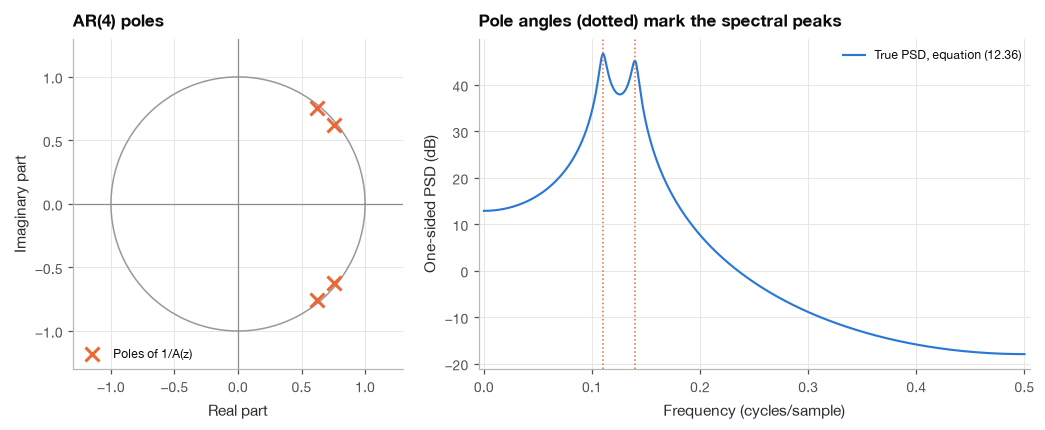

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(9.4, 3.8), gridspec_kw={"width_ratios": [1, 1.6]})
ax = axes[0]
circle = np.exp(1j * np.linspace(0, 2 * np.pi, 400))
ax.plot(circle.real, circle.imag, color="0.6", lw=1)
ax.plot(poles.real, poles.imag, "x", color=C[1], ms=9, mew=2, label="Poles of 1/A(z)")
ax.axhline(0, color="0.55", lw=0.8)
ax.axvline(0, color="0.55", lw=0.8)
ax.set(xlim=(-1.3, 1.3), ylim=(-1.3, 1.3), xlabel="Real part", ylabel="Imaginary part",
       title="AR(4) poles")
ax.set_aspect("equal")
ax.legend(loc="lower left", fontsize=8)

ax = axes[1]
ax.plot(f_grid, dB(S_true), color=C[0], label="True PSD, equation (12.36)")
for p in poles[poles.imag > 0]:
    ax.axvline(np.angle(p) / (2 * np.pi), color=C[1], ls=":", lw=1)
ax.set(xlabel="Frequency (cycles/sample)", ylabel="One-sided PSD (dB)",
       title="Pole angles (dotted) mark the spectral peaks")
ax.legend(loc="upper right", fontsize=8)
plt.show()

The two pole pairs sit at radii of about 0.98, very close to the unit circle, and their angles agree with the two spectral peaks to within a few thousandths of a cycle per sample. The peaks are not exactly at the pole angles because each pole also contributes to the level at the other peak, but the pole picture is an accurate guide.

There is a second, deeper way to see why AR estimates can be sharper than Welch estimates. The difference equation [(7.34)](#eq-7-34) also governs the autocorrelation (we prove this in the next subsection), so once $a_1, \ldots, a_p$ are known, the autocorrelation is determined at *every* lag, not just the lags we could estimate from the data. A Welch estimate implicitly sets the autocorrelation to zero beyond the segment length, which is what limits its resolution. An AR estimate extrapolates it with the model. {cite:t}`burg1975` showed that among all spectra consistent with the first $p + 1$ autocorrelation values, the AR($p$) spectrum is the one with maximum entropy, the one that assumes the least about the unknown lags. This is why AR spectral estimation is also called the **maximum entropy method**.

(sec-7-4-2)=
## 7.4.2 The Yule–Walker Equations

To estimate the coefficients we need equations that connect them to quantities we can measure. The autocorrelation is the natural candidate.

**Step 1: multiply by a past sample and take expectations.** Multiply both sides of [(7.34)](#eq-7-34) by $x[n - m]$ for some $m \ge 0$ and take the expectation. By stationarity $\mathbb{E}\{x[n-k]\,x[n-m]\} = R_x[m - k]$, so

$$
R_x[m] + \sum_{k=1}^{p} a_k\,R_x[m - k] = \mathbb{E}\{w[n]\,x[n-m]\}.
$$

**Step 2: evaluate the right-hand side.** Because $H(z)$ is causal, $x[n - m]$ is a combination of $w[n-m], w[n-m-1], \ldots$, innovations that occurred at or before time $n - m$. For $m \ge 1$ they all precede $w[n]$, and white noise is uncorrelated with its own past, so the right-hand side is zero. For $m = 0$, $x[n] = w[n] + (\text{terms in the past of } w)$, and only the first term correlates with $w[n]$, giving $\sigma^2$.

**Step 3: collect the equations.** For $m = 1, \ldots, p$ we obtain $p$ linear equations in the $p$ unknown coefficients, and $m = 0$ gives the noise variance:

(eq-7-37)=
\begin{equation*}
\sum_{k=1}^{p} a_k\,R_x[m - k] = -R_x[m], \quad m = 1, \ldots, p, \qquad\qquad \sigma^2 = R_x[0] + \sum_{k=1}^{p} a_k\,R_x[k]. \tag{7.37}
\end{equation*}

These are the **Yule–Walker equations**, named after the two statisticians who used them in the 1920s and 1930s to model sunspot numbers and other periodic-looking series. Using $R_x[-k] = R_x[k]$, the first set is the matrix equation

(eq-7-38)=
\begin{equation*}
\underbrace{\begin{bmatrix}
R_x[0] & R_x[1] & \cdots & R_x[p-1] \\
R_x[1] & R_x[0] & \cdots & R_x[p-2] \\
\vdots & \vdots & \ddots & \vdots \\
R_x[p-1] & R_x[p-2] & \cdots & R_x[0]
\end{bmatrix}}_{\mathbf{R}}
\begin{bmatrix} a_1 \\ a_2 \\ \vdots \\ a_p \end{bmatrix}
= -\begin{bmatrix} R_x[1] \\ R_x[2] \\ \vdots \\ R_x[p] \end{bmatrix}. \tag{7.38}
\end{equation*}

The matrix $\mathbf{R}$ is symmetric and **Toeplitz**: every diagonal is constant, because each entry depends only on the difference of its row and column indices. Note also that for $m > p$ the same argument gives $R_x[m] = -\sum_k a_k R_x[m - k]$: the autocorrelation obeys the same recursion as the signal, which is the extrapolation property mentioned above.

**Example 7.4.1.** Solve the Yule–Walker equations for $p = 1$.

With one unknown, [(7.38)](#eq-7-38) reads $R_x[0]\,a_1 = -R_x[1]$, so $a_1 = -R_x[1]/R_x[0] = -\rho_1$, the negative of the lag-one correlation coefficient. The variance equation gives $\sigma^2 = R_x[0] + a_1 R_x[1] = R_x[0](1 - \rho_1^2)$. For the AR(1) process of [Section 7.1](01_random_processes.ipynb#sec-7-1) with $R_x[k] = \sigma_w^2 a^{|k|}/(1 - a^2)$, we get $\rho_1 = a$, hence $a_1 = -a$ and $\sigma^2 = \frac{\sigma_w^2}{1 - a^2}(1 - a^2) = \sigma_w^2$, exactly the parameters that generated the process. Fitting an AR(1) model to an ECG noise record is thus as simple as computing its lag-one correlation.

**Estimating the coefficients.** In practice we replace $R_x[k]$ by the biased estimate $\hat{r}_x^{\,b}[k]$ of equation [(7.10)](01_random_processes.ipynb#eq-7-10) and solve. I always use the biased estimate here: it guarantees that the estimated matrix is positive definite, which in turn guarantees that the fitted $A(z)$ has all its roots inside the unit circle, so the fitted model is stable. A general linear solver costs $O(p^3)$ operations, but SciPy's `solve_toeplitz` exploits the structure and needs only $O(p^2)$, using the recursion of the next subsection.

In [4]:
def acorr_biased(x, max_lag):
    """Biased autocorrelation estimate r_b[k], k = 0..max_lag (equation 12.10)."""
    N = x.size
    return np.array([np.dot(x[:N - k], x[k:]) / N for k in range(max_lag + 1)])


def yule_walker(x, p):
    """AR(p) coefficients [1, a_1..a_p] and noise variance from the Yule-Walker equations (12.37)-(12.38)."""
    r = acorr_biased(x - x.mean(), p)
    a = solve_toeplitz(r[:p], -r[1:p + 1])
    return np.r_[1.0, a], r[0] + np.dot(a, r[1:p + 1])


N = 4096
x_long = signal.lfilter([1.0], a_true, rng.normal(0, 1, N + 3000))[3000:]
a_yw, s2_yw = yule_walker(x_long, 4)
print(f"true coefficients : {a_true[1:]},  sigma^2 = {sigma2_true:.3f}")
print(f"Yule-Walker, N={N}: {a_yw[1:]},  sigma^2 = {s2_yw:.3f}")
print(f"pole radii of the fit: {np.round(np.sort(np.abs(np.roots(a_yw))), 4)}")

true coefficients : [-2.7607  3.8106 -2.6535  0.9238],  sigma^2 = 1.000
Yule-Walker, N=4096: [-2.6719  3.6122 -2.4598  0.8464],  sigma^2 = 1.955
pole radii of the fit: [0.9558 0.9558 0.9626 0.9626]


With 4096 samples the coefficients come out close to the true values, although not exactly: the estimated poles are pulled slightly inward, a sign of the bias of $\hat{r}_x^{\,b}$ that becomes serious for short records, as we will see in [Section 7.4.5](#sec-7-4-5).

(sec-7-4-3)=
## 7.4.3 The Levinson–Durbin Recursion

The Levinson–Durbin recursion {cite:p}`levinson1947,durbin1960` solves [(7.38)](#eq-7-38) for orders $1, 2, \ldots, p$ in turn, each from the previous one, in $O(p^2)$ operations in total. Its by-products, the *reflection coefficients* and the prediction-error variances, are at least as useful as the speed.

Let $\mathbf{a}^{(m)} = [1, a_1^{(m)}, \ldots, a_m^{(m)}]^T$ be the solution of order $m$ and $E_m$ the corresponding noise variance (the mean squared one-step prediction error). Equations [(7.37)](#eq-7-37) for order $m$ can be written together as one $(m+1)\times(m+1)$ system,

$$
\mathbf{R}_{m+1}\,\mathbf{a}^{(m)} = \begin{bmatrix} E_m & 0 & \cdots & 0 \end{bmatrix}^T,
$$

where $\mathbf{R}_{m+1}$ is the Toeplitz matrix built from $R_x[0], \ldots, R_x[m]$: the first row is the variance equation, the others are the Yule–Walker equations.

**Step 1: use the symmetry.** A symmetric Toeplitz matrix is unchanged when we reverse the order of both rows and columns. Reversing the vector $\mathbf{a}^{(m)}$ (call it $\tilde{\mathbf{a}}^{(m)}$) therefore reverses the right-hand side: $\mathbf{R}_{m+1}\tilde{\mathbf{a}}^{(m)} = [0, \ldots, 0, E_m]^T$.

**Step 2: append a zero and grow the matrix.** Padding with a zero and multiplying by the next larger matrix $\mathbf{R}_{m+2}$ reproduces the old equations and adds one new row:

$$
\mathbf{R}_{m+2}\begin{bmatrix}\mathbf{a}^{(m)} \\ 0\end{bmatrix} = \begin{bmatrix} E_m \\ 0 \\ \vdots \\ 0 \\ \Delta_m \end{bmatrix}, \qquad
\mathbf{R}_{m+2}\begin{bmatrix} 0 \\ \tilde{\mathbf{a}}^{(m)}\end{bmatrix} = \begin{bmatrix} \Delta_m \\ 0 \\ \vdots \\ 0 \\ E_m \end{bmatrix}, \qquad
\Delta_m = R_x[m+1] + \sum_{k=1}^{m} a_k^{(m)} R_x[m+1-k].
$$

The new row produces a nonzero leftover $\Delta_m$, which is why the padded vector is not yet the order-$(m+1)$ solution.

**Step 3: combine to cancel the leftover.** For any number $k_{m+1}$, the combination $[\mathbf{a}^{(m)}; 0] + k_{m+1}[0; \tilde{\mathbf{a}}^{(m)}]$ produces the right-hand side $[E_m + k_{m+1}\Delta_m, 0, \ldots, 0, \Delta_m + k_{m+1}E_m]^T$. Choosing $k_{m+1} = -\Delta_m/E_m$ zeroes the last entry, and the result has exactly the form of the order-$(m+1)$ equations. Reading off the coefficients and the first entry,

(eq-7-39)=
\begin{equation*}
k_{m+1} = -\frac{\Delta_m}{E_m}, \qquad a_i^{(m+1)} = a_i^{(m)} + k_{m+1}\,a_{m+1-i}^{(m)}, \quad a_{m+1}^{(m+1)} = k_{m+1}, \qquad E_{m+1} = E_m\big(1 - k_{m+1}^2\big). \tag{7.39}
\end{equation*}

The recursion starts from $\mathbf{a}^{(0)} = [1]$ and $E_0 = R_x[0]$. The numbers $k_m$ are the **reflection coefficients** (the name comes from their interpretation in models of wave propagation in layered media, such as the vocal tract). The error update shows that $E_m$ can only decrease with order, and that $E_m > 0$ requires $|k_m| < 1$ at every stage. It can be shown that $|k_m| < 1$ for all $m$ is equivalent to all roots of $A(z)$ lying inside the unit circle, so the reflection coefficients are also a convenient stability test.

In [5]:
def levinson_durbin(r, p):
    """Solve the Yule-Walker equations by the Levinson-Durbin recursion (12.39)."""
    a, E, k = np.array([1.0]), r[0], np.zeros(p)
    for m in range(p):
        delta = r[m + 1] + np.dot(a[1:], r[m:0:-1])
        k[m] = -delta / E
        a_pad = np.r_[a, 0.0]
        a = a_pad + k[m] * a_pad[::-1]
        E *= 1 - k[m] ** 2
    return a, E, k


r = acorr_biased(x_long - x_long.mean(), 4)
a_ld, E_ld, k_ld = levinson_durbin(r, 4)
print(f"Levinson-Durbin     : {a_ld[1:]},  E_4 = {E_ld:.4f}")
print(f"solve_toeplitz      : {a_yw[1:]},  sigma^2 = {s2_yw:.4f}")
print(f"reflection coeffs   : {k_ld}")
print(f"max |difference|    : {np.max(np.abs(a_ld - a_yw)):.1e}")

Levinson-Durbin     : [-2.6719  3.6122 -2.4598  0.8464],  E_4 = 1.9547
solve_toeplitz      : [-2.6719  3.6122 -2.4598  0.8464],  sigma^2 = 1.9547
reflection coeffs   : [-0.7034  0.982  -0.6988  0.8464]
max |difference|    : 2.1e-13


(sec-7-4-4)=
## 7.4.4 Burg's Method

The Yule–Walker estimate inherits a weakness from $\hat{r}_x^{\,b}$: the biased autocorrelation is the autocorrelation of the data *padded with zeros* on both sides, and by [(7.24)](03_nonparametric_psd.ipynb#eq-7-24) its transform is the periodogram, with all the smoothing of the Fejér kernel. For long records this hardly matters. For short records of a process with sharp peaks, the poles are pulled toward the origin and the peaks are blunted. {cite:t}`burg1975` avoided the autocorrelation estimate altogether and estimated the reflection coefficients directly from the data, one stage at a time, keeping the Levinson structure [(7.39)](#eq-7-39) so that the model remains stable.

**Step 1: forward and backward prediction errors.** For the order-$m$ coefficients define the forward prediction error, the error of predicting $x[n]$ from the $m$ samples before it, and the backward prediction error, the error of predicting $x[n-m]$ from the $m$ samples after it:

$$
f_m[n] = \sum_{i=0}^{m} a_i^{(m)}\,x[n - i], \qquad b_m[n] = \sum_{i=0}^{m} a_i^{(m)}\,x[n - m + i], \qquad a_0^{(m)} = 1.
$$

For a stationary process the backward predictor uses the same coefficients as the forward one, because the autocorrelation is symmetric in time.

**Step 2: derive the lattice recursion.** Substituting the coefficient update of [(7.39)](#eq-7-39) into $f_m[n]$ splits it into two sums. The first is $f_{m-1}[n]$. In the second, $k_m\sum_i a_{m-i}^{(m-1)}x[n-i]$, we substitute $j = m - i$ and recognize $k_m\,b_{m-1}[n-1]$. The same manipulation applied to $b_m[n]$ gives the companion equation, so

(eq-7-40)=
\begin{equation*}
f_m[n] = f_{m-1}[n] + k_m\,b_{m-1}[n-1], \qquad b_m[n] = b_{m-1}[n-1] + k_m\,f_{m-1}[n], \tag{7.40}
\end{equation*}

starting from $f_0[n] = b_0[n] = x[n]$. This is the **lattice** form of the prediction-error filter.

**Step 3: choose $k_m$ to minimize the errors.** Burg chose $k_m$ to minimize the sum of forward and backward error energies over all $n$ for which both are computable from the data, $n = m, \ldots, N - 1$, without any zero padding:

$$
\mathcal{E}_m(k_m) = \sum_{n=m}^{N-1}\Big[\big(f_{m-1}[n] + k_m b_{m-1}[n-1]\big)^2 + \big(b_{m-1}[n-1] + k_m f_{m-1}[n]\big)^2\Big].
$$

This is a quadratic in $k_m$. Setting its derivative to zero, $2\sum\big[(f + k_m b)\,b + (b + k_m f)\,f\big] = 0$, with $f = f_{m-1}[n]$ and $b = b_{m-1}[n-1]$, and solving,

(eq-7-41)=
\begin{equation*}
k_m = \frac{-2\sum_{n=m}^{N-1} f_{m-1}[n]\,b_{m-1}[n-1]}{\sum_{n=m}^{N-1}\Big(f_{m-1}^2[n] + b_{m-1}^2[n-1]\Big)}. \tag{7.41}
\end{equation*}

Because $2|fb| \le f^2 + b^2$ for any real numbers, the numerator can never exceed the denominator in magnitude, so $|k_m| \le 1$ automatically and the Burg model is always stable. The coefficients then follow from the update in [(7.39)](#eq-7-39), and the noise variance from $E_m = E_{m-1}(1 - k_m^2)$ with $E_0$ the mean square of the data.

In [6]:
def burg(x, p):
    """Burg's AR(p) estimate: lattice recursion (12.40) with reflection coefficients (12.41)."""
    x = x - x.mean()
    f, b = x.copy(), x.copy()
    a, E, k = np.array([1.0]), np.mean(x**2), np.zeros(p)
    for m in range(p):
        ff, bb = f[1:], b[:-1]                 # f_{m-1}[n] and b_{m-1}[n-1], n = m..N-1
        k[m] = -2 * np.dot(ff, bb) / (np.dot(ff, ff) + np.dot(bb, bb))
        f, b = ff + k[m] * bb, bb + k[m] * ff
        a_pad = np.r_[a, 0.0]
        a = a_pad + k[m] * a_pad[::-1]
        E *= 1 - k[m] ** 2
    return a, E, k


a_bg, E_bg, k_bg = burg(x_long, 4)
print(f"true   : {a_true[1:]}")
print(f"Burg   : {a_bg[1:]},  sigma^2 = {E_bg:.3f}")
print(f"Yule-W.: {a_yw[1:]},  sigma^2 = {s2_yw:.3f}")
print(f"Burg pole radii: {np.round(np.sort(np.abs(np.roots(a_bg))), 4)}  "
      f"(true {np.round(np.sort(np.abs(poles)), 4)})")

true   : [-2.7607  3.8106 -2.6535  0.9238]
Burg   : [-2.7508  3.7944 -2.6394  0.9194],  sigma^2 = 1.006
Yule-W.: [-2.6719  3.6122 -2.4598  0.8464],  sigma^2 = 1.955
Burg pole radii: [0.9756 0.9756 0.9828 0.9828]  (true [0.9803 0.9803 0.9805 0.9805])


(sec-7-4-5)=
## 7.4.5 Recovering a Known Spectrum from a Short Record

The real test is a short record. We draw 200 independent records of only $N = 256$ samples from the AR(4) process, fit fourth-order models with both methods, and compare them with Welch estimates from the same data. The true order is known here; the next subsection removes that luxury.

In [7]:
N_short, n_rep = 256, 200
w_rep = rng.normal(0, 1, size=(n_rep, N_short + 3000))
x_rep = signal.lfilter([1.0], a_true, w_rep, axis=1)[:, 3000:]

S_yw = np.array([ar_spectrum(*yule_walker(x, 4), f_grid) for x in x_rep])
S_bg = np.array([ar_spectrum(*burg(x, 4)[:2], f_grid) for x in x_rep])
f_wl, S_wl = signal.welch(x_rep, fs=1.0, nperseg=64, axis=-1)


def peak_pair(S, f):
    """Frequencies of the two largest local maxima of a spectrum (NaN if fewer than two)."""
    idx, _ = signal.find_peaks(S)
    if idx.size < 2:
        return np.array([np.nan, np.nan])
    return np.sort(f[idx[np.argsort(S[idx])[-2:]]])


rows = []
for name, S, f in [("Yule-Walker AR(4)", S_yw, f_grid), ("Burg AR(4)", S_bg, f_grid), ("Welch, L = 64", S_wl, f_wl)]:
    pk = np.array([peak_pair(s, f) for s in S])
    resolved = ~np.isnan(pk[:, 0]) & (pk[:, 0] > 0.09) & (pk[:, 1] < 0.16)
    on_grid = np.interp(f_grid, f, np.median(S, axis=0))
    rows.append({"method": name, "two peaks resolved (%)": 100 * resolved.mean(),
                 "median error at 0.11 (dB)": dB(on_grid[np.argmin(abs(f_grid - 0.1102))] / S_true[np.argmin(abs(f_grid - 0.1102))]),
                 "median error at 0.40 (dB)": dB(on_grid[np.argmin(abs(f_grid - 0.4))] / S_true[np.argmin(abs(f_grid - 0.4))])})
print(pd.DataFrame(rows).round(1).to_string(index=False))

           method  two peaks resolved (%)  median error at 0.11 (dB)  median error at 0.40 (dB)
Yule-Walker AR(4)                     0.5                      -10.0                       19.7
       Burg AR(4)                   100.0                       -1.8                        0.1
    Welch, L = 64                    19.0                       -5.3                       -0.2


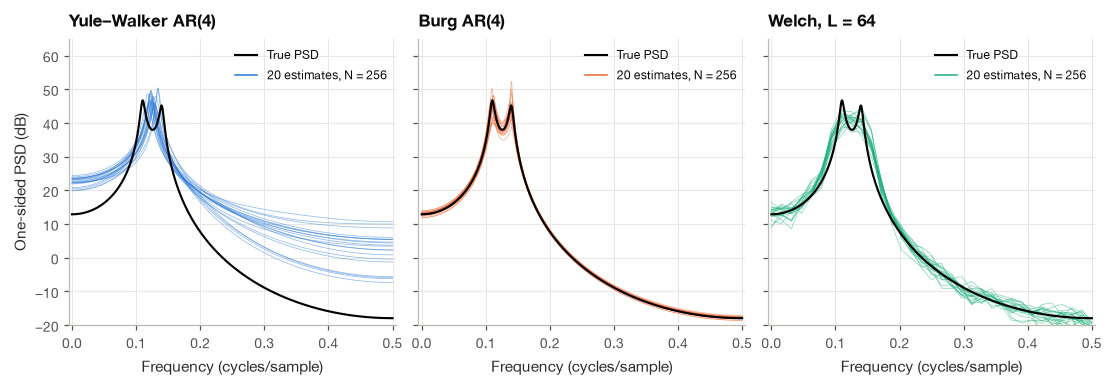

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(10, 3.4), sharey=True)
for ax, (name, S, f, col) in zip(axes, [("Yule–Walker AR(4)", S_yw, f_grid, C[0]),
                                        ("Burg AR(4)", S_bg, f_grid, C[1]),
                                        ("Welch, L = 64", S_wl, f_wl, C[2])]):
    for s in S[:20]:
        ax.plot(f, dB(s), color=col, lw=0.5, alpha=0.5)
    ax.plot(f_grid, dB(S_true), color="k", lw=1.4, label="True PSD")
    ax.plot([], [], color=col, lw=1, label="20 estimates, N = 256")
    ax.set(xlabel="Frequency (cycles/sample)", title=name, ylim=(-20, 65))
    ax.legend(loc="upper right", fontsize=8)
axes[0].set_ylabel("One-sided PSD (dB)")
plt.show()

The difference between the two AR methods is striking. With 256 samples Burg's method recovers both peaks in almost every record and follows the 60 dB fall of the spectrum, while the Yule–Walker estimates are visibly smoothed: the zero-padding implicit in $\hat{r}_x^{\,b}$ pulls the poles inward, so the two peaks are lowered and often merge into one. The Welch estimate, limited to a resolution of about $1.5/64 \approx 0.023$ cycles/sample, cannot separate peaks 0.03 cycles/sample apart and fills in the valley between them. For short records of sharply peaked processes, Burg's method is the one I would use, and it is the default AR method in most HRV software.

(sec-7-4-6)=
## 7.4.6 Choosing the Model Order

So far we cheated by using the true order. With real signals $p$ must be chosen from the data, and the choice matters. Too low an order cannot represent all the peaks; too high an order fits the random fluctuations of the particular record and produces spurious peaks, or splits one true peak into two. The prediction-error variance $E_p$ is no guide on its own, because by [(7.39)](#eq-7-39) it never increases with $p$.

**Final prediction error.** {cite:t}`akaike1969` asked a sharper question: how well would the fitted model predict a *new*, independent record from the same process? A rough argument shows the structure of his answer. Fitting $p$ coefficients to $N$ samples uses up about $p$ degrees of freedom, so the in-sample error underestimates the true innovation variance, $\mathbb{E}\{E_p\} \approx \sigma^2(1 - p/N)$. Applied to new data, the estimation errors in the coefficients add to the innovation variance instead, giving an out-of-sample error of about $\sigma^2(1 + p/N)$. Eliminating the unknown $\sigma^2$ between the two expressions gives the **final prediction error**

(eq-7-42)=
\begin{equation*}
\operatorname{FPE}(p) = E_p\,\frac{N + p}{N - p}, \tag{7.42}
\end{equation*}

which first decreases with $p$, as the model captures more structure, and then increases, as the penalty factor takes over. (Akaike's original version uses $N + p + 1$ and $N - p - 1$ to count the estimated mean as an extra parameter; the difference is negligible for $N \gg p$.)

**Akaike's information criterion.** The more general information criterion {cite:p}`akaike1974`, derived from the expected Kullback–Leibler distance between the fitted model and the truth, takes for a Gaussian AR model the form

(eq-7-43)=
\begin{equation*}
\operatorname{AIC}(p) = N\ln E_p + 2p. \tag{7.43}
\end{equation*}

The two criteria are close relatives: for $p \ll N$, $\ln\frac{N+p}{N-p} \approx \frac{2p}{N}$, so $N\ln\operatorname{FPE}(p) \approx \operatorname{AIC}(p)$. Both are known to overestimate the order somewhat for long records; variants with heavier penalties, such as the minimum description length $N\ln E_p + p\ln N$, choose smaller orders. I treat the criteria as a guide, not an oracle, and always look at the spectra of neighboring orders before settling.

In [9]:
def order_criteria(x, p_max):
    """FPE (12.42) and AIC (12.43) for Burg fits of orders 1..p_max."""
    N = x.size
    _, _, k = burg(x, p_max)
    E = np.mean((x - x.mean()) ** 2) * np.cumprod(1 - k**2)          # E_1 .. E_pmax from (12.39)
    p = np.arange(1, p_max + 1)
    return p, E * (N + p) / (N - p), N * np.log(E) + 2 * p


p_axis, fpe, aic = order_criteria(x_rep[0], 30)
print(f"Order chosen by FPE: {p_axis[np.argmin(fpe)]}, by AIC: {p_axis[np.argmin(aic)]}")
chosen = [p_axis[np.argmin(order_criteria(x, 30)[2])] for x in x_rep[:100]]
print(f"AIC choice over 100 records of N = 256: "
      f"{pd.Series(chosen).value_counts().sort_index().to_dict()}")

Order chosen by FPE: 4, by AIC: 4
AIC choice over 100 records of N = 256: {4: 82, 5: 5, 6: 4, 8: 3, 10: 2, 13: 1, 14: 1, 15: 1, 17: 1}


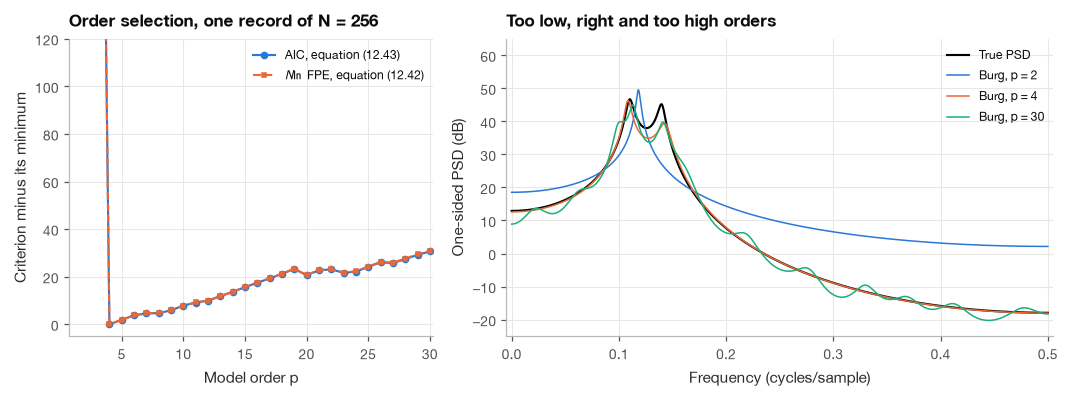

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(9.6, 3.5), gridspec_kw={"width_ratios": [1, 1.5]})
ax = axes[0]
ax.plot(p_axis, aic - aic.min(), "o-", color=C[0], ms=4, label="AIC, equation (12.43)")
ax.plot(p_axis, N_short * np.log(fpe) - N_short * np.log(fpe).min(), "s--", color=C[1], ms=3,
        label=r"$N \ln$ FPE, equation (12.42)")
ax.set(xlabel="Model order p", ylabel="Criterion minus its minimum", ylim=(-5, 120),
       title="Order selection, one record of N = 256")
ax.legend(loc="upper right", fontsize=8)

ax = axes[1]
ax.plot(f_grid, dB(S_true), color="k", lw=1.4, label="True PSD")
for p, col in [(2, C[0]), (4, C[1]), (30, C[2])]:
    a_p, E_p, _ = burg(x_rep[0], p)
    ax.plot(f_grid, dB(ar_spectrum(a_p, E_p, f_grid)), color=col, lw=1, label=f"Burg, p = {p}")
ax.set(xlabel="Frequency (cycles/sample)", ylabel="One-sided PSD (dB)", ylim=(-25, 65),
       title="Too low, right and too high orders")
ax.legend(loc="upper right", fontsize=8)
plt.show()

(sec-7-4-7)=
## 7.4.7 Applied Example: Short Records of Heart Rhythm and EEG

Two classic uses of AR spectra in physiology are short-term heart rate variability and short EEG epochs. Both are situations where Welch's method is starved of data.

### Step 1: Build an evenly sampled RR series

An RR series is sampled at the beats, which are unevenly spaced in time. To apply any of our spectral methods we first resample it on a regular grid. The usual recipe {cite:p}`taskforce1996` is to keep only intervals between two normal beats (NN intervals), place each one at the time of its second beat, interpolate with a cubic spline, and resample at 4 Hz, comfortably above the 0.4 Hz upper edge of the HRV high-frequency band. We take the first five minutes of MIT-BIH record 100 {cite:p}`moody2001,goldberger2000`.

In [11]:
ann = wfdb.rdann("../data/mitdb/100", "atr", sampto=310 * 360)
is_beat = np.isin(ann.symbol, ["N", "L", "R", "A", "a", "J", "S", "V", "F", "e", "j", "E", "/", "f", "Q"])
t_beat = ann.sample[is_beat] / 360.0
sym = np.array(ann.symbol)[is_beat]
nn = (sym[1:] == "N") & (sym[:-1] == "N")
t_nn, rr_ms = t_beat[1:][nn], 1000 * np.diff(t_beat)[nn]

fs_rr = 4.0
t_grid = np.arange(np.ceil(t_nn[0]), t_nn[0] + 300, 1 / fs_rr)
rr_grid = CubicSpline(t_nn, rr_ms)(t_grid)
rr_det = signal.detrend(rr_grid, type="linear")
print(f"{nn.sum()} NN intervals kept of {nn.size}, mean RR {rr_ms.mean():.0f} ms, SDNN {rr_ms.std():.1f} ms")
print(f"resampled series: {rr_grid.size} samples at {fs_rr:.0f} Hz ({rr_grid.size / fs_rr:.0f} s)")

375 NN intervals kept of 383, mean RR 809 ms, SDNN 25.3 ms
resampled series: 1197 samples at 4 Hz (299 s)


### Step 2: Welch and AR spectra of five minutes and of one minute

For the five-minute series, Welch's method with 64 s segments (256 samples) gives a resolution of $1.5/64 \approx 0.023$ Hz and only about 8 segments. For a one-minute piece the best Welch can do is a single 30 s segment pair. The AR model order is chosen by AIC with an upper limit of 20.

In [12]:
f_hrv = np.linspace(0, 0.5, 1001)
hrv = {}
for label, x in [("5 min", rr_det), ("1 min", signal.detrend(rr_grid[:240]))]:
    p_ax, _, aic_rr = order_criteria(x, 20)
    p_rr = p_ax[np.argmin(aic_rr)]
    a_rr, E_rr, _ = burg(x, p_rr)
    L = 256 if label == "5 min" else 120
    f_w, S_w = signal.welch(x, fs=fs_rr, nperseg=L)
    hrv[label] = dict(p=p_rr, S_ar=ar_spectrum(a_rr, E_rr, f_hrv, fs_rr), f_w=f_w, S_w=S_w)
    print(f"{label}: AIC order {p_rr:2d}; Welch with L = {L} samples, {x.size // (L // 2) - 1} segments")


def band(f, S, lo, hi):
    """Power of a one-sided PSD in [lo, hi) Hz (trapezoidal rule)."""
    m = (f >= lo) & (f < hi)
    return np.trapezoid(S[m], f[m])


rows = []
for label, d in hrv.items():
    for meth, f, S in [("Welch", d["f_w"], d["S_w"]), (f"Burg AR({d['p']})", f_hrv, d["S_ar"])]:
        lf, hf = band(f, S, 0.04, 0.15), band(f, S, 0.15, 0.40)
        rows.append({"record": label, "method": meth, "LF (ms^2)": lf, "HF (ms^2)": hf, "LF/HF": lf / hf,
                     "HF peak (Hz)": f[(f >= 0.15) & (f < 0.4)][np.argmax(S[(f >= 0.15) & (f < 0.4)])]})
print(pd.DataFrame(rows).round(3).to_string(index=False))

5 min: AIC order 20; Welch with L = 256 samples, 8 segments
1 min: AIC order 20; Welch with L = 120 samples, 3 segments
record      method  LF (ms^2)  HF (ms^2)  LF/HF  HF peak (Hz)
 5 min       Welch     15.038    445.083  0.034         0.172
 5 min Burg AR(20)     45.006    499.211  0.090         0.168
 1 min       Welch     43.050    305.798  0.141         0.167
 1 min Burg AR(20)     60.941    506.763  0.120         0.165


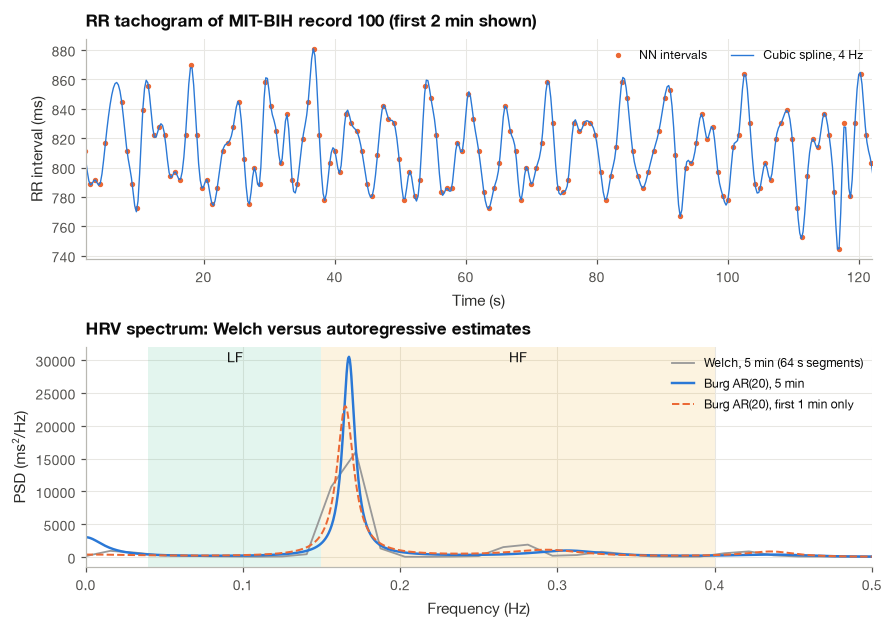

In [13]:
fig, axes = plt.subplots(2, 1, figsize=(8, 5.6))
axes[0].plot(t_nn, rr_ms, "o", color=C[1], ms=2.5, label="NN intervals")
axes[0].plot(t_grid, rr_grid, color=C[0], lw=0.9, label="Cubic spline, 4 Hz")
axes[0].set(xlabel="Time (s)", ylabel="RR interval (ms)", xlim=(t_grid[0], t_grid[0] + 120),
            title="RR tachogram of MIT-BIH record 100 (first 2 min shown)")
axes[0].legend(loc="upper right", fontsize=8, ncols=2)

ax = axes[1]
ax.axvspan(0.04, 0.15, color=C[2], alpha=0.12, lw=0)
ax.axvspan(0.15, 0.40, color=C[3], alpha=0.12, lw=0)
ax.text(0.095, 0.93, "LF", transform=ax.get_xaxis_transform(), ha="center", fontsize=9)
ax.text(0.275, 0.93, "HF", transform=ax.get_xaxis_transform(), ha="center", fontsize=9)
d5, d1 = hrv["5 min"], hrv["1 min"]
ax.plot(d5["f_w"], d5["S_w"], color="0.6", lw=1.2, label="Welch, 5 min (64 s segments)")
ax.plot(f_hrv, d5["S_ar"], color=C[0], lw=1.6, label=f"Burg AR({d5['p']}), 5 min")
ax.plot(f_hrv, d1["S_ar"], color=C[1], lw=1.3, ls="--", label=f"Burg AR({d1['p']}), first 1 min only")
ax.set(xlim=(0, 0.5), xlabel="Frequency (Hz)", ylabel="PSD (ms$^2$/Hz)",
       title="HRV spectrum: Welch versus autoregressive estimates")
ax.legend(loc="upper right", fontsize=8)
plt.show()

### Step 3: Read the HRV spectra

The five-minute AR spectrum is a smooth curve with a clear HF peak, the signature of respiratory sinus arrhythmia: heart rate rises during inspiration and falls during expiration, so the RR series oscillates at the breathing frequency. The Welch estimate from the same five minutes follows the AR curve on average but jitters around it, because eight segments leave a variance of roughly $1/8$ of the PSD squared. The two methods give band powers of the same order, which is reassuring, but they are not identical, and this is a known practical issue: published HRV values computed with AR and FFT methods should not be mixed {cite:p}`taskforce1996`. The one-minute AR spectrum places the HF peak close to where the five-minute estimate puts it, from a quarter of the data. That is the practical advantage of the parametric approach. Its absolute level is less reliable, as the band powers show, because one minute contains only a dozen breaths.

### Step 4: Two-second EEG epochs

For the EEG we return to the eyes-closed recording of [Section 7.3.8](03_nonparametric_psd.ipynb#sec-7-3-8), channel O1, and cut it into 30 non-overlapping epochs of 2 s (320 samples). For each epoch we estimate the individual alpha frequency, the frequency of the largest peak between 7 and 14 Hz, in two ways: from a Hann-windowed periodogram, zero-padded to a 0.05 Hz grid so that the peak is not quantized to the 0.5 Hz bins, and from a Burg AR model. A single model order for all epochs keeps the comparison simple; I take the median of the AIC choices.

In [14]:
raw = mne.io.read_raw_edf("../data/eegmmidb/S001R02.edf", preload=True)
mne.datasets.eegbci.standardize(raw)
o1 = raw.get_data(picks=["O1"])[0] * 1e6
fs_eeg = raw.info["sfreq"]
L_ep = int(2 * fs_eeg)
epochs = o1[:30 * L_ep].reshape(30, L_ep)

p_eeg = int(np.median([np.argmin(order_criteria(ep, 30)[2]) + 1 for ep in epochs]))
f_e = np.arange(0, fs_eeg / 2 + 1e-9, 0.05)
alpha_win = (f_e >= 7) & (f_e <= 14)
nfft = int(round(fs_eeg / 0.05))
iaf = {"Periodogram (Hann)": [], f"Burg AR({p_eeg})": []}
S_ep_pg, S_ep_ar = [], []
for ep in epochs:
    _, S_pg = signal.periodogram(ep, fs=fs_eeg, window="hann", nfft=nfft, detrend="constant")
    a_e, E_e, _ = burg(ep, p_eeg)
    S_ar = ar_spectrum(a_e, E_e, f_e, fs_eeg)
    S_ep_pg.append(S_pg)
    S_ep_ar.append(S_ar)
    iaf["Periodogram (Hann)"].append(f_e[alpha_win][np.argmax(S_pg[alpha_win])])
    iaf[f"Burg AR({p_eeg})"].append(f_e[alpha_win][np.argmax(S_ar[alpha_win])])

f_ref, S_ref = signal.welch(o1, fs=fs_eeg, nperseg=int(8 * fs_eeg), nfft=nfft)
iaf_ref = f_ref[(f_ref >= 7) & (f_ref <= 14)][np.argmax(S_ref[(f_ref >= 7) & (f_ref <= 14)])]
print(f"Model order (median AIC choice over epochs): {p_eeg}")
print(f"Reference IAF from the whole minute (Welch, 8 s segments): {iaf_ref:.2f} Hz")
for name, v in iaf.items():
    v = np.array(v)
    print(f"{name:20s}: IAF mean {v.mean():.2f} Hz, SD across epochs {v.std():.2f} Hz, "
          f"range {v.min():.2f}-{v.max():.2f} Hz")

Model order (median AIC choice over epochs): 13
Reference IAF from the whole minute (Welch, 8 s segments): 9.95 Hz
Periodogram (Hann)  : IAF mean 10.08 Hz, SD across epochs 0.42 Hz, range 9.25-10.95 Hz
Burg AR(13)         : IAF mean 10.05 Hz, SD across epochs 0.32 Hz, range 9.55-10.70 Hz


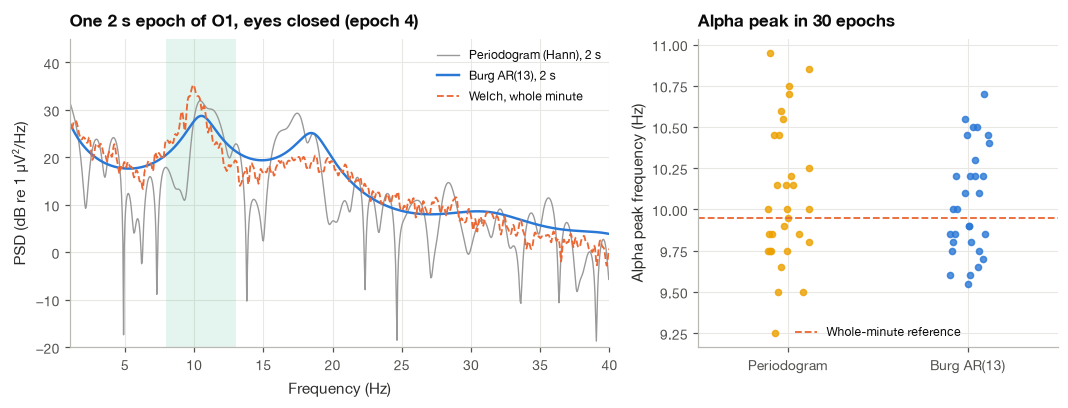

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(9.6, 3.6), gridspec_kw={"width_ratios": [1.5, 1]})
ax = axes[0]
i_show = 3
ax.plot(f_e, dB(S_ep_pg[i_show]), color="0.6", lw=0.9, label="Periodogram (Hann), 2 s")
ax.plot(f_e, dB(S_ep_ar[i_show]), color=C[0], lw=1.6, label=f"Burg AR({p_eeg}), 2 s")
ax.plot(f_ref, dB(S_ref), color=C[1], lw=1.2, ls="--", label="Welch, whole minute")
ax.axvspan(8, 13, color=C[2], alpha=0.12, lw=0)
ax.set(xlim=(1, 40), ylim=(-20, 45), xlabel="Frequency (Hz)", ylabel="PSD (dB re 1 µV$^2$/Hz)",
       title=f"One 2 s epoch of O1, eyes closed (epoch {i_show + 1})")
ax.legend(loc="upper right", fontsize=8)

ax = axes[1]
for j, (name, v) in enumerate(iaf.items()):
    ax.plot(np.full(30, j) + rng.uniform(-0.12, 0.12, 30), v, "o", color=[C[3], C[0]][j], ms=4, alpha=0.8)
ax.axhline(iaf_ref, color=C[1], ls="--", lw=1.2, label="Whole-minute reference")
ax.set(xticks=[0, 1], xticklabels=["Periodogram", f"Burg AR({p_eeg})"], xlim=(-0.5, 1.5),
       ylabel="Alpha peak frequency (Hz)", title="Alpha peak in 30 epochs")
ax.legend(loc="lower center", fontsize=8)
plt.show()

### Step 5: Interpret

On a single two-second epoch the periodogram is the familiar ragged curve, while the AR spectrum is smooth and places a single well-defined peak in the alpha band, close to the peak of the whole-minute Welch estimate. Across the 30 epochs the AR estimates of the alpha frequency scatter less than the periodogram estimates, because the model averages the information in the whole epoch into a pole position instead of picking the tallest of several noisy bins. This is why AR models have long been popular for tracking the dominant frequency of short EEG epochs, and why they are used as features in brain–computer interfaces.

(sec-7-4-8)=
## 7.4.8 Caveats

AR spectra look clean, and that is part of the danger: a smooth curve invites more confidence than it deserves. The main pitfalls, discussed at length by {cite:t}`kay1988` and {cite:t}`marple1987`, are these.

- **The model is an assumption.** An all-pole model represents peaks well and valleys poorly. Spectra with deep notches (a signal after a notch filter, for example) or with broad flat regions need high orders, and a moving-average or ARMA model would be more natural. When the AR assumption is wrong, the estimate is biased in ways that no confidence interval reveals.
- **Additive noise flattens peaks.** An AR process observed in white measurement noise is no longer AR; its spectrum is $\sigma^2/|A|^2 + \sigma_v^2$, which has zeros as well as poles. A low-order AR fit then blunts and broadens the peaks, so the resolution advantage shrinks as the signal-to-noise ratio falls.
- **Order selection is fragile.** AIC and FPE can disagree, and their minima are often shallow. Too high an order produces spurious peaks; for nearly sinusoidal components, a high order can split one peak into two ("line splitting"). I always compare neighboring orders.
- **Peak heights are not powers.** The height of an AR peak grows without bound as its pole approaches the unit circle, while its width shrinks. Power must be obtained by integrating the spectrum over a band, never by reading the height of a peak.
- **Stationarity still matters.** A short record makes AR estimation possible; it does not make a nonstationary signal stationary. If the heart rate drifts during the record, both Welch and AR spectra describe an average.

My own practice follows from these points. I use Welch's method by default, because its assumptions are few and its uncertainty is easy to state, and I switch to Burg's method when the records are short and the spectrum is known to be peaky, as for RR series, short EEG epochs and the dominant frequency of EMG during fatiguing contractions. When both are possible, I compute both, and I treat disagreement as information.

## Summary

An autoregressive model describes a signal as white noise passed through an all-pole filter $1/A(z)$, so by $S_y = |H|^2 S_x$ its spectrum is $\sigma^2/|A(e^{j\Omega})|^2$, a smooth curve whose peaks sit at the angles of poles near the unit circle. Multiplying the model by past samples and taking expectations gives the Yule–Walker equations, a symmetric Toeplitz system that links the coefficients to the autocorrelation; the Levinson–Durbin recursion solves it order by order in $O(p^2)$ operations and yields the reflection coefficients and prediction-error variances as by-products. Burg's method estimates the reflection coefficients directly from forward and backward prediction errors, avoids the zero padding hidden in the biased autocorrelation, and always gives a stable model. On a short record of a sharply peaked AR(4) process, Burg's method resolved two close peaks that both Yule–Walker and Welch merged. The model order is chosen with criteria such as FPE and AIC, which penalize the extra parameters that would otherwise fit noise. On real data, AR spectra gave a clean HRV spectrum from a one-minute RR series and a more stable alpha-frequency estimate from two-second EEG epochs than the periodogram.

The AR model will reappear in several roles. The prediction-error filter $A(z)$ is a whitening filter, which links this section to the Wiener filter of [Section 10.2](../ch16_noise_removal/02_wiener_filter.ipynb) and the adaptive filters of Section 16.3; AR spectra are used for HRV in Section 19.2; and AR coefficients serve as compact features for machine learning in Chapter 27.

## Exercises

1. Show that the AR(2) process $x[n] - 2r\cos\Omega_0\,x[n-1] + r^2 x[n-2] = w[n]$ has poles at $re^{\pm j\Omega_0}$. Write its PSD using [(7.35)](#eq-7-35) and find the frequency at which it is largest. For which values of $r$ and $\Omega_0$ does the peak lie exactly at $\Omega_0$?
2. Write out the Yule–Walker equations [(7.38)](#eq-7-38) for $p = 2$ and solve them by hand in terms of $\rho_1 = R_x[1]/R_x[0]$ and $\rho_2 = R_x[2]/R_x[0]$. Then run two steps of the Levinson–Durbin recursion [(7.39)](#eq-7-39) on the same quantities and confirm that you obtain the same coefficients. Express $k_1$ and $k_2$ in terms of $\rho_1$ and $\rho_2$.
3. Prove that $E_p = R_x[0]\prod_{m=1}^{p}(1 - k_m^2)$. Using the AR(4) test process, compute the reflection coefficients from the true autocorrelation and verify that all have magnitude less than one.
4. Repeat the experiment of [Section 7.4.5](#sec-7-4-5) for $N = 64, 128, 256, 1024$ and plot the percentage of records in which each method resolves the two peaks. At what length does the Yule–Walker estimate become competitive with Burg's?
5. Add white noise to the AR(4) process at signal-to-noise ratios of 30, 20 and 10 dB, fit Burg models of order 4 and of the order chosen by AIC, and describe how the peaks change. Relate your observations to the second caveat in [Section 7.4.8](#sec-7-4-8).
6. (Applied.) Compute the AR and Welch HRV spectra for six consecutive five-minute windows of record 100 and plot LF power, HF power and the HF peak frequency against time for both methods. Which quantities agree between the methods, and which do not?

## Further Reading

{cite:t}`kay1988` is the standard text on modern spectral estimation and treats AR, MA and ARMA estimators, Burg's method and order selection in depth; {cite:t}`marple1987` is equally thorough and includes careful comparisons on test signals such as the one used here. {cite:t}`stoica2005` (Chapter 3) gives a compact modern account of parametric methods, and {cite:t}`burg1975` and {cite:t}`akaike1974` are the original sources for the maximum entropy method and the information criterion. For the use of AR spectra in heart rate variability, start with the guidelines of the {cite:t}`taskforce1996`.